# DS111 · Mean, Median, Mode khi điền khuyết

**Câu hỏi.** Kiểu biến, hình dạng phân phối, ngoại lệ và mục tiêu đánh giá ảnh hưởng thế nào đến lựa chọn một giá trị điền?

Notebook dùng **649 dòng quan sát thực tế** từ tệp môn tiếng Bồ Đào Nha của UCI Student Performance. Bản gốc đầy đủ giúp biết giá trị tại mỗi ô trước khi che. Notebook tái tạo mặt nạ, hình và bảng từ seed 42. Phần EDA mô tả một bảng quan sát ở mức thiếu danh nghĩa 15%. Benchmark lấy một lần chia train/test riêng để chấm trên ô test bị che. [Nguồn UCI, CC BY 4.0](https://archive.ics.uci.edu/dataset/320/student-performance)

Bối cảnh môn học dựa trên mô tả slide 14–17 của `Bai04_EDA.pdf` trong đặc tả. Không lấy được PDF gốc qua liên kết Drive. Xem phần mở rộng và các nguồn ở [references.md](../presentation/references.md).

In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
from IPython.display import Image, display
from sklearn.impute import SimpleImputer

current = Path.cwd()
root = next(
    (p for p in (current, *current.parents) if (p / "src" / "run_experiments.py").is_file()),
    None,
)
if root is None:
    raise FileNotFoundError("Mở notebook trong project hoặc đặt thư mục làm việc tại project.")
sys.path.insert(0, str(root))
from src.prepare_data import CATEGORY, NUMERIC, demo_data, load_complete
from src.run_experiments import describe_demo, run

def figure(name):
    display(Image(filename=str(root / "figures" / f"{name}.png"), width=900))

evidence = run(root)
complete = load_complete(root)
observed, demo_mask = demo_data(complete)
print(f"Số hàng: {len(complete):,}. Số cột phân tích: {demo_mask.shape[1]}.")

Số hàng: 649. Số cột phân tích: 4.


## 1. Thiếu dữ liệu và phân tích đơn biến

`NaN`, `None` hoặc `pd.NA` biểu thị thiếu trong các kiểu dữ liệu khác nhau. Tài liệu miền quyết định chuỗi rỗng, `?`, `-999` có cần chuẩn hóa hay không. Giá trị 0 có thể là quan sát hợp lệ. Thiếu có thể đến từ bỏ trống câu hỏi, thiết bị lỗi, nhập liệu hoặc câu hỏi không áp dụng. Tính tỷ lệ thiếu cột $j$ bằng $m_j/N$. Nhiều phép tóm tắt bỏ qua NaN, từ đó có thể làm lệch mẫu dùng để suy luận.

Các biến được chọn gồm `G1` (điểm kỳ đầu), `absences` (số buổi vắng), `G3` (điểm cuối kỳ) và `guardian` (người giám hộ). Giữ `school` quan sát đầy đủ. Che Bernoulli độc lập với giá trị (MCAR). Với MAR, xác suất thiếu có thể phụ thuộc phần quan sát. Với MNAR, phần chưa quan sát vẫn ảnh hưởng sau khi xét phần quan sát. Biểu đồ và tỷ lệ thiếu chỉ cung cấp dấu hiệu để đặt câu hỏi về cơ chế.

,số ô thiếu,tỷ lệ thiếu
G1,113,17.41%
absences,94,14.48%
G3,97,14.95%
guardian,94,14.48%
school,0,0.00%


,count,mean,median,mode,std,min,max,skewness,iqr_flag_count
variable,,,,,,,,,
G1,536.0,11.349,11.0,10,2.720,0.0,19.0,0.012,14.0
absences,555.0,3.706,2.0,0,4.664,0.0,32.0,2.082,18.0
G3,552.0,11.846,12.0,11,3.311,0.0,19.0,-1.003,16.0


,tần suất
guardian,
mother,390
father,134
other,31


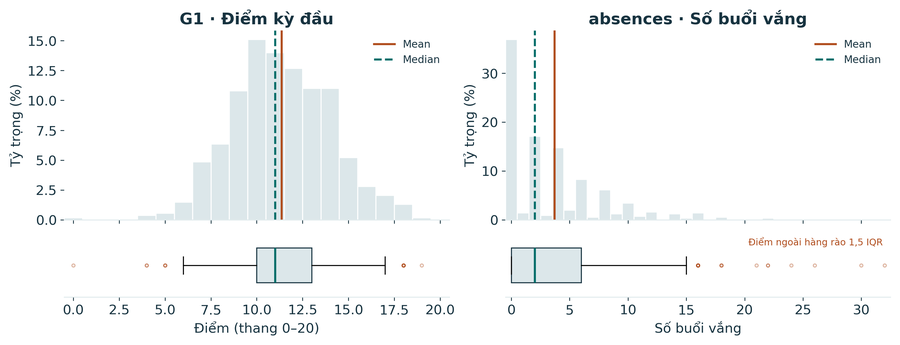

In [2]:
missing = pd.DataFrame({"số ô thiếu": observed.isna().sum(), "tỷ lệ thiếu": observed.isna().mean()})
display(missing.style.format({"tỷ lệ thiếu": "{:.2%}"}))
eda = pd.DataFrame(evidence["eda"]).set_index("variable")
display(eda[["count", "mean", "median", "mode", "std", "min", "max", "skewness", "iqr_flag_count"]].round(3))
display(observed[CATEGORY].value_counts().rename("tần suất").to_frame())
figure("eda_numeric")

Đọc histogram và boxplot cùng nhau. G1 gần đối xứng ở vùng trung tâm và Mean khá gần Median, song vẫn có điểm ngoài hàng rào 1,5 IQR. Với số buổi vắng, đuôi kéo sang phải, Mean cao hơn Median. Hàng rào 1,5 IQR gắn cờ để xem xét. Số buổi vắng bằng 0 là quan sát hợp lệ. Histogram dùng khoảng theo đơn vị nguyên để giữ đặc điểm rời rạc của điểm và số buổi vắng.

## 2. Chọn thống kê thay thế theo kiểu biến và mục tiêu

- **Mean** $\bar{x}=\frac{1}{n}\sum_{i=1}^{n}x_i$ dùng mọi độ lớn quan sát. Khi một quan sát đổi thêm $\Delta$, Mean đổi $\Delta/n$.
- **Median** là vị trí giữa sau khi sắp xếp. Với $n$ chẵn lấy trung bình hai vị trí giữa. Thứ hạng giúp Median bền hơn trước giá trị cực đoan.
- **Mode** là giá trị có tần suất cực đại. Với dữ liệu liên tục, đỉnh mật độ hoặc khoảng histogram có thể hữu ích hơn phép đếm trùng khớp. Nhiều giá trị có thể đồng hạng.

Ký hiệu đuôi điển hình là skewness dương cho đuôi phải và âm cho đuôi trái. Thứ tự trên hình là tính chất của các phân phối minh họa cụ thể. Đối xứng còn có thể gặp ở tam giác và hỗn hợp hai cụm. Xem thêm [NIST về skewness](https://www.itl.nist.gov/div898/handbook/eda/section3/eda35b.htm).

| Bằng chứng quan sát | Phương pháp nên thử | Vì sao và cần kiểm chứng gì |
|---|---|---|
| Định lượng gần đối xứng, ít ngoại lệ | Mean | Dùng độ lớn của mọi quan sát. Kiểm tra miền giá trị và RMSE. |
| Định lượng lệch hoặc nhiều điểm cực đoan | Median | Bền theo thứ hạng. Kiểm tra MAE, RMSE và đỉnh nhân tạo. |
| Định tính | Mode | Nhãn phổ biến nhất. Kiểm tra đa Mode và lớp hiếm. |
| Nhóm quan sát được, phân phối khác nhau | Thống kê theo nhóm | Giữ sự khác biệt có ý nghĩa. Kiểm tra nhóm hiếm, cột nhóm và leakage. |
| Nhiều đỉnh hoặc đồng hạng Mode | Phân tích cấu trúc trước | Cân nhắc thống kê có điều kiện và công bố quy tắc hòa. |

Đây là các điểm bắt đầu. Chọn theo ngữ nghĩa, biểu đồ, mức độ thiếu và mục tiêu, thay vì đặt ngưỡng skewness hoặc tỷ lệ thiếu chung.

Age: Mean = 34, Median = 23.
Size: Mode = ['M'].
Đa Mode: [2, 8], Mean = 4.6, Median = 3.


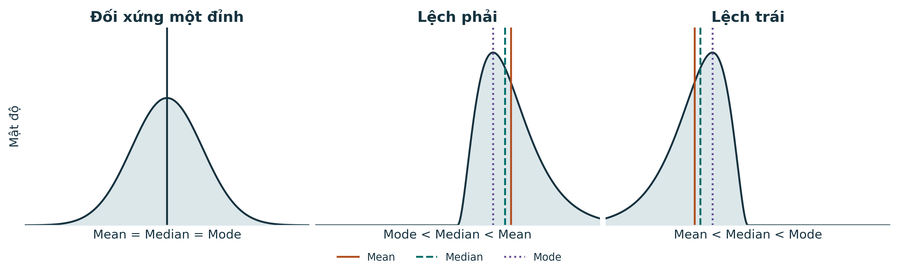

In [3]:
figure("distribution_theory")
age = pd.Series([20, 22, 23, 25, 80, np.nan])
size = pd.Series(["M", "M", "L", "S", np.nan, "M"])
tie = pd.Series([2, 2, 3, 8, 8, np.nan])
print(f"Age: Mean = {age.mean():g}, Median = {age.median():g}.")
print(f"Size: Mode = {size.mode().tolist()}.")
print(f"Đa Mode: {tie.mode().astype(int).tolist()}, Mean = {tie.mean():g}, Median = {tie.median():g}.")

Tuổi 80 cao so với cụm 20–25 trong mẫu nhỏ này và có thể là quan sát hợp lệ. Nếu muốn một giá trị thay thế gần cụm, 23 là một lựa chọn minh họa. Tuổi thật bị che vẫn chưa biết. Size là nhãn, nên phép cộng mã số sẽ phụ thuộc cách mã hóa. Ví dụ đa Mode có hai mốt. `most_frequent` chọn giá trị nhỏ nhất khi hòa, là một quy tắc ổn định cần công bố. [SimpleImputer](https://scikit-learn.org/stable/modules/generated/sklearn.impute.SimpleImputer.html)

## 3. Điền bằng SimpleImputer trong demo EDA

Fit từ phần quan sát của chính bảng để xem điều gì thay đổi trong bảng. Phần minh họa này phục vụ so sánh phân phối.

Mean: điền 3.706306306306306, sau điền còn 0 ô thiếu.
Median: điền 2.0, sau điền còn 0 ô thiếu.
Mode: điền mother, sau điền còn 0 ô thiếu.


,stage,count,mean,median,std,variance,missing_rate
1,Complete,649,3.6595,2.0000,4.6408,21.5366,0.0000
4,Observed,555,3.7063,2.0000,4.6636,21.7493,0.1448
7,Mean,649,3.7063,3.7063,4.3121,18.5943,0.0000
10,Median,649,3.4592,2.0000,4.3538,18.9555,0.0000


stage,Complete,Mode,Observed
category,,,
father,153,134,134
mother,455,484,390
other,41,31,31


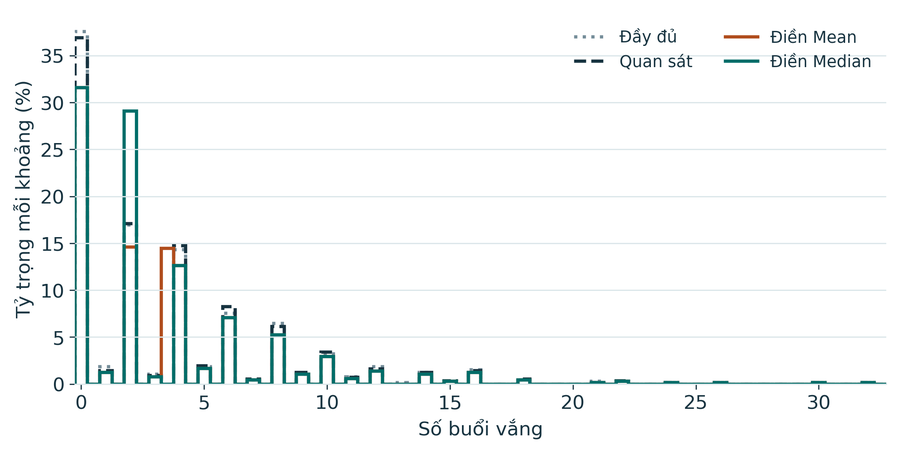

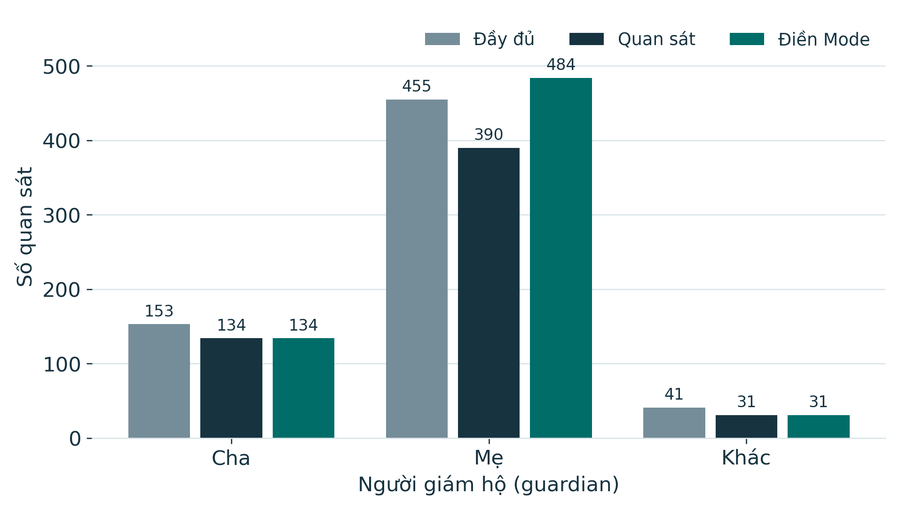

In [4]:
mean_imputer = SimpleImputer(strategy="mean")
median_imputer = SimpleImputer(strategy="median")
mode_imputer = SimpleImputer(strategy="most_frequent")
skew = NUMERIC[1]
for label, imputer, variable in [
    ("Mean", mean_imputer, skew), ("Median", median_imputer, skew), ("Mode", mode_imputer, CATEGORY),
]:
    result = imputer.fit_transform(observed[[variable]])
    print(f"{label}: điền {imputer.statistics_[0]}, sau điền còn {pd.isna(result).sum()} ô thiếu.")

stages, distribution, category_frequencies = describe_demo(complete, observed)
display(distribution.query("variable == @skew").drop(columns=["variable", "corr_school_GP"]).round(4))
display(category_frequencies.pivot(index="category", columns="stage", values="count"))
figure("numeric_imputation_before_after")
figure("categorical_mode")

Mean giữ Mean quan sát trong demo vì mọi ô điền có độ lệch bằng 0 so với Mean đó. Với $n$ ô quan sát và $m$ ô điền, phương sai mẫu trở thành $s^2_{\rm obs}(n-1)/(n+m-1)$ khi $n\ge2$. Công thức này so sánh với phần quan sát đã dùng để tính Mean. Mean từ train có thể khác Mean quan sát của test. Giá trị Mean lẻ của số buổi vắng được giữ để chấm dự đoán điểm. Nếu đầu ra phải là số đếm, hãy kiểm thử riêng quy tắc làm tròn. Median và Mode làm tăng tần suất tại giá trị điền. Điền hằng số toàn cục có thể làm suy yếu liên hệ với trường.

## 4. Benchmark trên ô test bị che

1. Chia 75/25 theo hàng từ dữ liệu đầy đủ.
2. Với mỗi mức 5%, 15%, 30%, tạo 12 bộ mặt nạ train và test từ hai luồng RNG độc lập. Mỗi cặp phương pháp dùng cùng mặt nạ.
3. Fit trên train đã che rồi transform test đã che. Chỉ lấy ground truth ở ô test có mask True.
4. Với $k$ ô test che và $e_i=\hat{x}_i-x_i$, MAE là $\sum|e_i|/k$, RMSE là $\sqrt{\sum e_i^2/k}$. Với nhãn, Accuracy là số khớp chia cho $k$.

SD đi kèm điểm trung bình đo sự dao động theo mặt nạ, trên cùng lần chia. Sai số điểm thấp không bảo đảm bảo toàn hình dạng hoặc liên hệ giữa các biến. [scikit-learn về data leakage](https://scikit-learn.org/stable/common_pitfalls.html#data-leakage)

metric                          Accuracy          MAE         RMSE
variable method                                                   
G1       Mean                          —  2.41 ± 0.36  2.99 ± 0.44
         Median                        —  2.44 ± 0.35  3.07 ± 0.44
G3       Group Median                  —  2.35 ± 0.31  3.19 ± 0.52
         Mean                          —  2.43 ± 0.25  3.19 ± 0.47
         Median                        —  2.42 ± 0.25  3.17 ± 0.48
absences Mean                          —  2.83 ± 0.36  3.69 ± 0.81
         Median                        —  2.52 ± 0.47  3.86 ± 0.93
guardian Mode          68.87% ± 6.54 đpt            —            —

missing_rate                     0.05   0.15   0.30
variable method       metric                       
G1       Mean         MAE       2.444  2.407  2.481
                      RMSE      2.955  2.987  3.073
         Median       MAE       2.494  2.438  2.501
                      RMSE      3.034  3.067  3.133
G3       Group Median MAE       2.024  2.348  2.405
                      RMSE      2.799  3.193  3.295
         Mean         MAE       2.388  2.433  2.507
                      RMSE      2.953  3.187  3.314
         Median       MAE       2.381  2.417  2.497
                      RMSE      2.933  3.167  3.306
absences Mean         MAE       2.539  2.832  2.956
                      RMSE      3.152  3.690  3.922
         Median       MAE       2.294  2.521  2.670
                      RMSE      3.077  3.856  4.095
guardian Mode         Accuracy  0.635  0.689  0.692

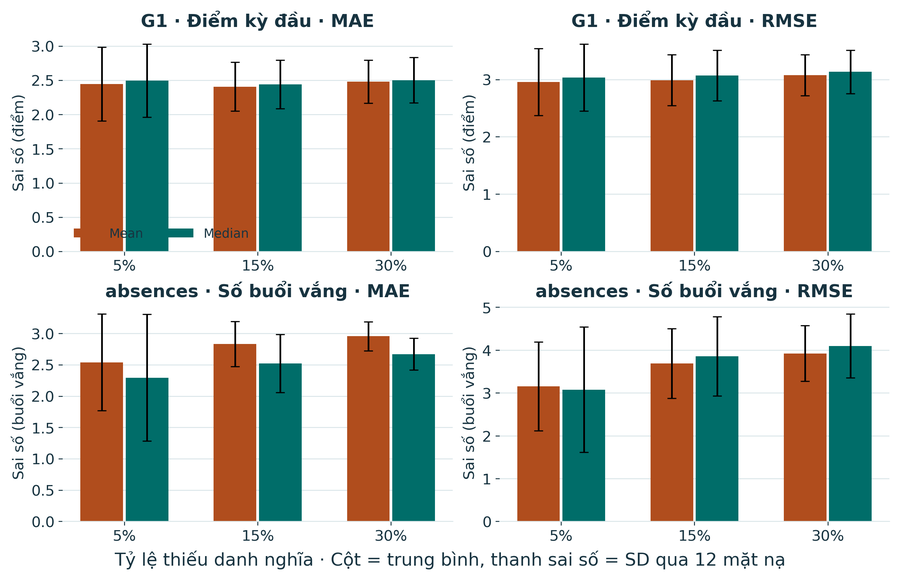

In [5]:
scores = pd.DataFrame(evidence["scores"])
focus = scores.loc[scores.missing_rate.eq(0.15)].copy()
focus["mean ± SD"] = focus.apply(
    lambda r: f"{r['mean']:.2%} ± {r['std'] * 100:.2f} đpt" if r["metric"] == "Accuracy"
    else f"{r['mean']:.2f} ± {r['std']:.2f}", axis=1,
)
display(focus.pivot(index=["variable", "method"], columns="metric", values="mean ± SD").fillna("—"))
display(scores.pivot_table(index=["variable", "method", "metric"], columns="missing_rate", values="mean").round(3))
figure("imputation_errors")

Với cùng một hằng số, tối thiểu hóa sai số tuyệt đối dẫn đến Median trên tập dùng để tối ưu. Tối thiểu hóa bình phương sai số dẫn đến Mean. Trên `absences` tại mức 15%, Median có MAE thấp hơn và Mean có RMSE thấp hơn. Hai lựa chọn cho điểm gần nhau trên `G1`. Accuracy khi điền mọi ô che bằng nhãn `mother` bằng tỷ lệ nhãn này trong các ô test bị che. Các nhãn `father` và `other` trong phần che bị điền sai.

## 5. Khác biệt theo trường và giới hạn

Điểm G3 ở GP và MS có phân phối chồng lấn, với Median toàn tập lần lượt là 13 và 11. Đồ thị dùng tỷ trọng trong mỗi trường vì số dòng giữa hai trường khác nhau. Nếu biết trường khi áp dụng, có thể học Median theo trường trên train. Nhóm chưa gặp hoặc dưới 20 quan sát dùng Median train toàn cục. Ở mức 15%, phương pháp theo trường có MAE thấp hơn một chút và RMSE tương tự. Chênh lệch điểm quan sát không xác lập tác động nhân quả của trường.

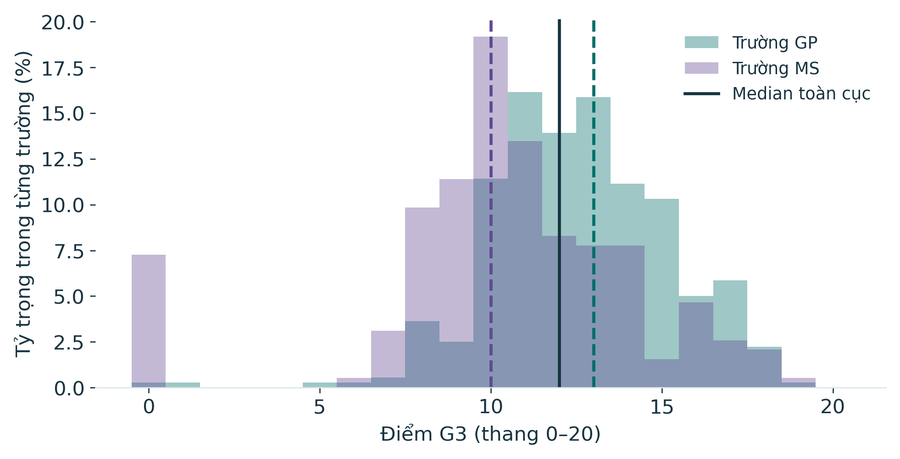

,school,size,median
0,GP,423,13.0
1,MS,226,11.0


,stage,mean,median,std,corr_school_GP
2,Complete,11.906,12.000,3.2307,0.2843
5,Observed,11.846,12.000,3.3108,0.3104
8,Mean,11.846,11.846,3.0530,0.2865
11,Median,11.869,12.000,3.0535,0.2866


In [6]:
figure("g3_by_school")
multi = NUMERIC[2]
display(pd.DataFrame(evidence["schools"]))
display(distribution.loc[distribution.variable.eq(multi), ["stage", "mean", "median", "std", "corr_school_GP"]].round(4))

**Kết luận.** Xác định kiểu biến và cơ chế thiếu khả dĩ, kiểm tra phân phối trước khi chọn thống kê, rồi đánh giá cả sai số và biến dạng sau khi điền. Giá trị điền là một ước lượng. Khi dữ liệu thiếu có hệ thống, mỗi nhóm thiếu nhiều hoặc cần suy luận bất định, nên kiểm tra độ nhạy và cân nhắc phương pháp có điều kiện hoặc multiple imputation. Benchmark này giới hạn ở mẫu môn tiếng Bồ Đào Nha và các mặt nạ MCAR đã mô tả.